Simple Linear Regression with sklearn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression

Read data into data frame form csv dataset

In [2]:
data = pd.read_csv("real_estate_price_size.csv")
data.head()

,price,size
0,234314.144,643.09
1,228581.528,656.22
2,281626.336,487.29
3,401255.608,1504.75
4,458674.256,1275.46


declearing dependent and independent variable 

In [3]:
x = data['size']
y = data['price']

In [4]:
x.shape

(100,)

In [6]:
y.shape

(100,)

In order to feed x to sklearn, It should be a 2D array (a matrix). Therefore we must reshape it. 
NOTE: This will not be needed when we've got more than 1 feature (as the input will be a 2D array by default).

In [8]:
x_matrix = x.values.reshape(-1, 1)
x_matrix.shape

(100, 1)

creating an object of LinearRegression

In [9]:
reg = LinearRegression()

fitting the varibale into the model 

In [10]:
reg.fit(x_matrix, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[223.18]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.019e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[2964.48]


R-square

In [11]:
reg.score(x_matrix, y)

0.7447391865847587

Coefficent

In [12]:
reg.coef_

array([223.17874259])

Intercept

In [13]:
reg.intercept_

np.float64(101912.60180122912)

Predict the price when size is 1300

In [16]:
print(f"price of property when size is 1300 is: {reg.predict([[1300]])[0]}")

price of property when size is 1300 is: 392044.9671742187


In [17]:
new_data = pd.DataFrame({'size': [1420, 1399]})
new_data

,size
0,1420
1,1399


creating a column for predicted price 

In [18]:
new_data['predicted_price'] = reg.predict(new_data)
new_data

c:\Python313\Lib\site-packages\sklearn\utils\validation.py:2823: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


,size,predicted_price
0,1420,418826.416286
1,1399,414139.662691


Let's create a scatter plot for given data

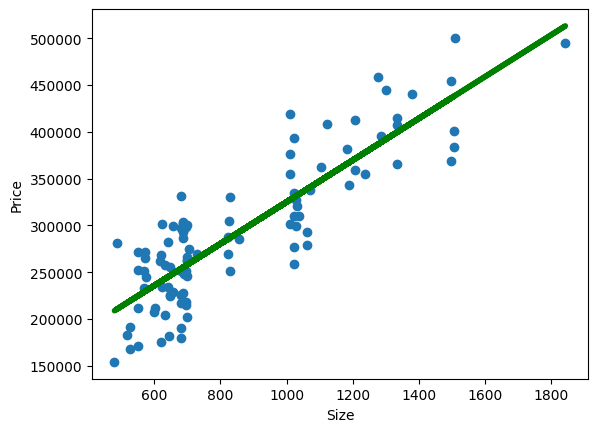

In [19]:
plt.scatter(x, y)
yhat = reg.coef_ * x_matrix + reg.intercept_
fig = plt.plot(x, yhat, lw = 4, c = 'green', label = 'regression line')
plt.xlabel('Size', fontsize = 10)
plt.ylabel('Price', fontsize = 10)
plt.show()